# 05 · Machine learning: LightGBM trained on all 20 companies

**What LightGBM does.** In the ML course (Course 2, Week 4) a **decision tree** asks yes/no questions about the inputs ("was last year's growth above 5 %?") and ends in a leaf with a prediction. **Boosting** (XGBoost) builds many small trees one after another, each trained on what the trees before it still got wrong. LightGBM is a fast version of that idea. Here: 200 small trees (at most 8 leaves, at least 20 rows per leaf), each adding only 5 % of its correction (the learning rate). The forecast is the sum of all those small corrections.

**What's new compared with ETS and ARIMA:** those fit one company at a time. LightGBM learns **one pattern from all 20 companies together**.

**Target:** growth vs the same quarter last year, h quarters ahead, in logs. **Features**, all known at the origin: the last 4 year-on-year growths, the last quarter-on-quarter growth, which fiscal quarter the target is, and company type. No company name and no 2020 flag. **Forecast** = same quarter last year × exp(predicted growth).

**Fixed before any run (CLAUDE.md):** one model per horizon, retrained at every company origin on all rows (from any company) that were public by its cutoff; `num_leaves` 8, `min_data_in_leaf` 20, learning rate 0.05, 200 trees, seed 0, no tuning. Same setup as Session 4: fiscal quarters, first origin after 5 years, 65-day rule, first-reported revenue. Alphabet is scored without the Motorola targets.

**Main tests (fixed before evaluating):**
1. One quarter ahead: in how many of the 20 companies does LightGBM beat ETS?
2. Full year: in how many of the 20 does it beat the company's best simple rule?

Code: `src/features.py`, `src/lgbm.py`, `src/evaluate_lgbm.py`. The forecasts were made by `lgbm.py run` (about 3.5 minutes) and saved in `results/session5_lgbm_forecasts.csv`.

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from companies import TYPES
from features import build_table, describe_example
from lgbm import worked_example, leak_check, OUT as LGBM_FORECASTS
from evaluate_types import best_rules, load_forecasts
from evaluate_lgbm import (ALL, all_methods, per_company, main_tests, by_type, all_horizons,
                           importance, average_growth_placebo, year_2020, sign_test)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
f = all_methods()
rules = best_rules(load_forecasts())
t = per_company(f, rules)

## 1. The feature table and one example row

In [2]:
table = build_table()
print(f"{len(table):,} rows (company x origin x horizon) from 20 companies")
describe_example(table)

5,555 rows (company x origin x horizon) from 20 companies
Mattel, origin 2013Q1, h = 1: predict growth of 2013Q2 vs 2012Q2
  target  = log(rev 2013Q2) - log(rev 2012Q2) = +0.0089  (+0.9 %)
  yoy_0   = 2013Q1 vs 2012Q1: +0.0698  (+7.2 %)
  yoy_1   = 2012Q4 vs 2011Q4: +0.0463  (+4.7 %)
  yoy_2   = 2012Q3 vs 2011Q3: +0.0388  (+4.0 %)
  yoy_3   = 2012Q2 vs 2011Q2: -0.0025  (-0.3 %)
  qoq     = 2013Q1 vs 2012Q4: -0.8180  (-55.9 %)
  target_quarter = 2   type = Seasonal
  public_date = 2013-07-25  (the last quarter used became public then)


## 2. Worked example: Mattel at its first origin ($m)
LightGBM next to B2 (same quarter last year × last year's growth, its simple version) and ETS.

In [3]:
worked_example("Mattel")

Mattel, first origin 2013Q1: we pretend it is 2013-06-04

  h  target  train rows  pred. growth   base (same q. last yr)  LightGBM        B2       ETS
  1  2013Q2         283         +7.7%         2012Q2 = 1,158.7   1,247.4   1,204.3   1,212.7
  2  2013Q3         283         +4.2%         2012Q3 = 2,077.8   2,165.0   2,159.5   2,058.6
  3  2013Q4         284         +3.8%         2012Q4 = 2,255.9   2,340.9   2,344.6   2,186.9
  4  2014Q1         284         +2.0%           2013Q1 = 995.6   1,015.4   1,034.7     963.7

  LightGBM = base x exp(predicted log growth); all in $m.
  What the h = 1 model leaned on (share of total split gain): yoy_0 78%, qoq 7%, yoy_2 5%, yoy_1 5%, yoy_3 4%, type 0%, target_quarter 0%


**What this shows:** at Mattel's first origin (June 2013), the models had only 283 training rows from all 20 companies. LightGBM predicted Q2 2013 growth of +7.7 %, so its forecast is last year's Q2 × 1.077 = $1,247 m, a little above B2 ($1,204 m) and ETS ($1,213 m). The h = 1 model leaned almost entirely on the latest year-on-year growth (78 % of its splitting gain).

## 3. Leak check on every forecast
All counts must be 0: no training row may have been public after the cutoff, and the row we forecast from may only use quarters public by then.

In [4]:
g = pd.read_csv(LGBM_FORECASTS, parse_dates=["cutoff", "train_max_public", "row_public"])
for col in ["origin", "target"]:
    g[col] = pd.PeriodIndex(g[col], freq="Q")
leak_check(g)

forecasts                                              4036
training data public after the cutoff                     0
forecast row uses a quarter public after the cutoff       0
target not after the origin                               0
dtype: int64

## 4. Main tests
A **sign test** asks: if LightGBM and the other method were equally good, each would win about half of the 20 companies, like a coin. How unlikely is the count we see? Two-sided, so a lopsided count in *either* direction counts.

**Caveat:** the 20 companies share shocks (2020 above all), so their results aren't fully independent. That makes the p-values somewhat too optimistic.

In [5]:
main_tests(t).round(4)

,companies,LightGBM wins,sign test p (two-sided)
test,,,
h=1: LightGBM beats ETS,20,2,0.00
full year: LightGBM beats the best simple rule,20,11,0.82


**What this shows:** one quarter ahead, LightGBM beats ETS for only **2 of 20** companies (Salesforce and Adobe). If they were equally good, a count that lopsided would happen by chance only 0.04 % of the time, so **LightGBM is reliably *worse* than ETS** one quarter ahead (even allowing for shared shocks, the margin is large). For the full year it beats the best simple rule for **11 of 20**, a coin flip (p = 0.82), the same as ETS did in Session 4.

## 5. Per company
MAPE in % at h = 1 and for the full year, with Diebold–Mariano p-values, not corrected and listed for information only.

In [6]:
t.round(2)

,type,best rule,h1 LGBM,h1 ETS,p vs ETS,h1 B2,p vs B2,FY LGBM,FY rule,p FY vs rule,FY ETS,beats ETS h1,beats rule FY,beats B2 h1
company,,,,,,,,,,,,,,
Mattel,Seasonal,B1,8.04,7.49,0.52,8.92,0.33,7.20,6.36,0.44,6.93,False,False,True
Hasbro,Seasonal,B2,10.39,10.14,0.85,10.25,0.91,10.40,11.08,0.81,9.74,False,True,False
Williams-Sonoma,Seasonal,B2,3.78,3.66,0.82,5.65,0.00,4.08,6.69,0.08,4.04,False,True,True
Best Buy,Seasonal,B2,4.47,4.07,0.49,6.03,0.07,5.82,7.63,0.17,4.63,False,True,True
Macy's,Seasonal,B2,6.32,5.25,0.02,8.86,0.02,5.86,9.67,0.15,6.10,False,True,True
Alphabet,Growth tech,B2,3.73,3.41,0.52,5.66,0.01,5.53,7.19,0.30,5.88,False,True,True
Microsoft,Growth tech,B2,4.54,3.83,0.19,5.68,0.04,5.63,6.44,0.31,6.44,False,True,True
Salesforce,Growth tech,B2,1.91,2.39,0.17,2.65,0.02,2.70,3.04,0.62,4.31,True,True,True
Netflix,Growth tech,B2,2.20,2.14,0.83,3.59,0.00,4.08,4.31,0.80,5.41,False,True,True


**What this shows:** LightGBM's losses to ETS are mostly small, under 1 point for 14 of its 18 losses, but larger for Clorox (7.7 vs 5.0 %), Deere (7.5 vs 5.5 %), Macy's (6.3 vs 5.3 %) and P&G (3.5 vs 2.4 %). For the full year it beats the best simple rule clearly where that rule was weak (the seasonal retailers, Deere), and loses where the rule was already good (Caterpillar, Cummins, Clorox). None of the uncorrected p-values changes the main picture.

## 6. By type

In [7]:
by_type(t).round(2)

,h1 LGBM,h1 ETS,h1 B2,FY LGBM,FY rule,FY ETS,beats ETS h1,beats B2 h1,beats rule FY
type,,,,,,,,,
Seasonal,6.60,6.12,7.94,6.67,8.29,6.29,0/5,4/5,4/5
Growth tech,2.97,2.88,4.19,4.40,4.97,5.43,2/5,5/5,4/5
Cyclical industrial,6.61,5.75,11.29,9.88,9.88,8.79,0/5,5/5,1/5
FMCG,4.01,2.95,4.35,3.94,3.61,3.26,0/5,4/5,2/5


**What this shows:** one quarter ahead, LightGBM loses to ETS in every type (it wins only 2 of 5 growth companies). For the full year it beats the best simple rule for 4 of 5 seasonal and growth companies but only 1 of 5 cyclicals and 2 of 5 FMCG companies. Even where it wins, ETS's full-year error is about as low or lower (Seasonal 6.3 vs 6.7 %).

## 7. LightGBM vs B2, its simple version
B2 says: same quarter last year × last year's growth. LightGBM starts from the same quarter last year too, but *learns* how much growth to expect from all 20 companies' histories.

In [8]:
w = int(t["beats B2 h1"].sum()); gap = t["h1 B2"] - t["h1 LGBM"]
print(f"LightGBM beats B2 at h = 1 for {w} of 20 companies (sign test p = {sign_test(w, 20):.4f}); "
      f"median gain {gap.median():.2f} MAPE points, range {gap.min():.2f} to {gap.max():.2f}")
all_horizons(f).round(2)

LightGBM beats B2 at h = 1 for 18 of 20 companies (sign test p = 0.0004); median gain 1.27 MAPE points, range -0.14 to 5.91


"mean MAPE over all forecasts, %",B0,B1,B2,ETS,LGBM
h,,,,,
1,11.87,10.33,6.95,4.41,5.04
2,15.70,10.40,8.45,6.25,6.91
3,14.57,10.46,9.55,7.67,8.06
4,10.54,10.54,10.50,8.87,9.14


**What this shows:** against B2, its simple version, LightGBM wins for **18 of 20** companies (p = 0.0004), typically by 1.3 MAPE points, and by up to 6 points for the cyclicals. So learning how much of last year's growth carries over helps a lot: B2 assumes all of it does. Across all forecasts, LightGBM sits between B2 and ETS at every horizon (h = 1: B2 7.0 %, LightGBM 5.0 %, ETS 4.4 %).

## 8. Sanity check (placebo): does LightGBM learn anything from its features?
The same forecast without any features: base × exp(the *average* growth of all training rows public by the cutoff). If LightGBM can't beat this, its features add nothing.

In [9]:
p = average_growth_placebo(f)
print(f"LightGBM better than the no-feature placebo for {int(p['LGBM better'].sum())} of 20 companies")
p.round(2)

LightGBM better than the no-feature placebo for 20 of 20 companies


,h1 LGBM,h1 average-growth placebo,LGBM better
company,,,
Mattel,8.04,12.28,True
Hasbro,10.39,12.78,True
Williams-Sonoma,3.78,5.94,True
Best Buy,4.47,9.87,True
Macy's,6.32,14.22,True
Alphabet,3.73,10.42,True
Microsoft,4.54,8.33,True
Salesforce,1.91,12.11,True
Netflix,2.20,12.08,True


**What this shows:** the no-feature version (last year's quarter × average growth) misses by 10.3 % on average; LightGBM by 5.1 %, and it's better for all 20 companies. So the features carry real information, and LightGBM is learning something. It just doesn't learn enough to beat ETS, which starts from the *latest* quarter rather than last year's.

## 9. What the models lean on (feature importance)
The share of the total *split gain* (how much each feature's questions reduced the error) in the final model for each horizon, trained on every public row.

In [10]:
importance().round(1)

,h=1,h=2,h=3,h=4
yoy_0,79.60,59.50,39.70,24.30
yoy_3,7.20,6.40,11.60,18.00
qoq,5.00,7.10,12.70,8.60
yoy_1,2.70,5.20,13.60,8.80
yoy_2,2.70,14.00,4.60,8.30
type,2.60,7.20,16.60,31.60
target_quarter,0.10,0.50,1.20,0.40


**What this shows:** one quarter ahead, the model relies almost entirely on **the latest year-on-year growth** (80 % of the gain): roughly "next quarter grows about as fast as this quarter did, a bit less". Company type hardly matters at h = 1 (3 %) but becomes the single biggest feature at h = 4 (32 %): further out, the model falls back on "what kind of company is this?" (growth companies keep growing). The target quarter barely matters, because the target is already measured against the same quarter last year.

## 10. The year 2020
h = 1 MAPE for targets ending in calendar 2020 vs all other targets.

In [11]:
year_2020(f).round(1)

baseline               B2               ETS              LGBM            
when                 2020 other years  2020 other years  2020 other years
type                                                                     
Seasonal            15.80        7.40 13.60        5.60 16.90        5.90
Growth tech          4.50        4.10  3.80        2.80  4.30        2.90
Cyclical industrial 20.70       10.50 17.30        4.80 14.10        6.00
FMCG                 5.80        4.20  4.90        2.80  4.30        4.00

**What this shows:** in 2020, LightGBM did *better* than ETS for cyclical companies (14.1 vs 17.3 %) and FMCG (4.4 vs 4.9 %), and worse for seasonal retailers (16.9 vs 13.6 %). Learning from 20 companies seems to help in a shared shock, where one company's own history is misleading. In normal years ETS is better in every type.

## 11. Summary chart
h = 1 MAPE per company, grouped by type: ETS, LightGBM and B2.

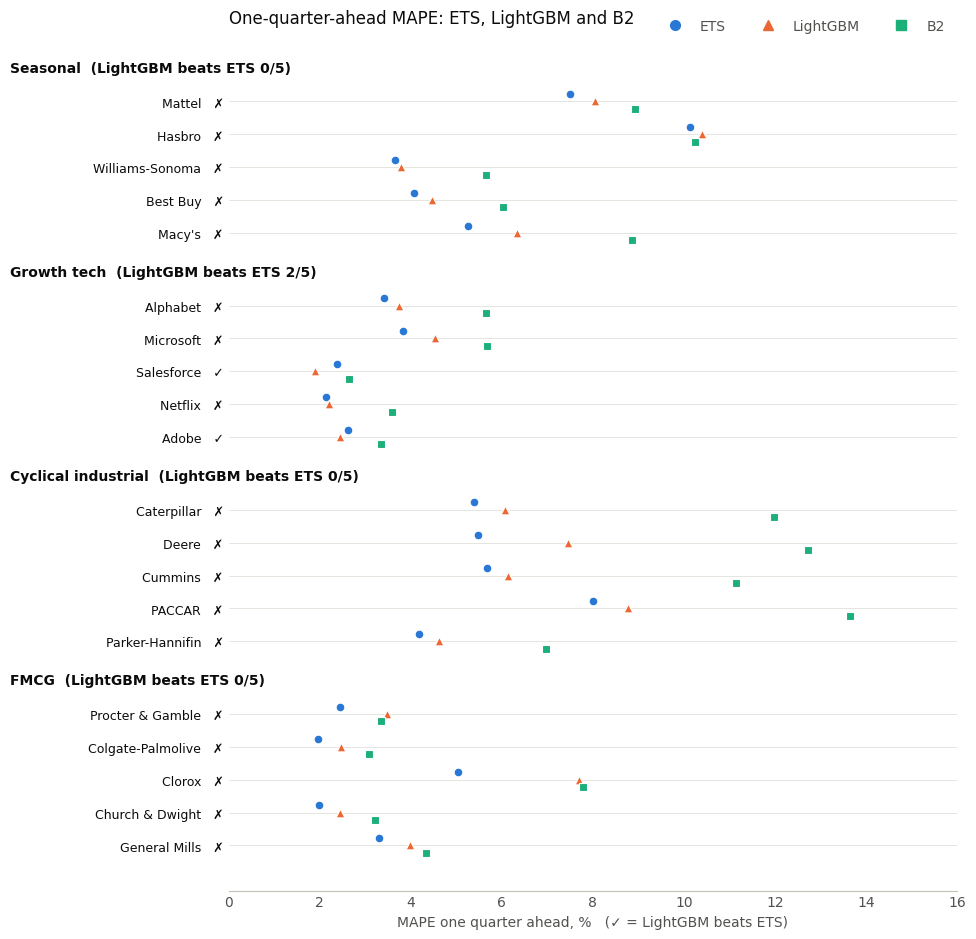

In [12]:
ETSC, LGC, B2C = "#2a78d6", "#eb6834", "#1baf7a"     # default palette slots 1-3
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
STYLE = {"ETS": (ETSC, "o", "h1 ETS"), "LightGBM": (LGC, "^", "h1 LGBM"), "B2": (B2C, "s", "h1 B2")}
OFFSET = {"ETS": -0.22, "LightGBM": 0.0, "B2": 0.22}
LIMIT = 16

rows, y = [], 0
for ty in TYPES:
    for c in [c for c in ALL if t.loc[c, "type"] == ty]:
        rows.append((y, c)); y += 1
    y += 1.2
fig, ax = plt.subplots(figsize=(10, 9.5))
for yy, c in rows:
    ax.hlines(yy, 0, LIMIT, color=GRID, lw=0.6, zorder=0)
    for m, (col, mk, field) in STYLE.items():
        v = t.loc[c, field]
        ax.scatter(min(v, LIMIT), yy + OFFSET[m], color=col, marker=mk, s=40, edgecolor="white", lw=0.8, zorder=3)
labels = [f"{c}   {'✓' if t.loc[c, 'beats ETS h1'] else '✗'}" for _, c in rows]
ax.set_yticks([r[0] for r in rows], labels, fontsize=9, color=INK)
ax.invert_yaxis()
for ty in TYPES:
    ys = [yy for yy, c in rows if t.loc[c, "type"] == ty]
    wins = int(t[t["type"] == ty]["beats ETS h1"].sum())
    ax.text(-0.3, min(ys) - 0.9, f"{ty}  (LightGBM beats ETS {wins}/5)", transform=ax.get_yaxis_transform(),
            color=INK, fontsize=10, fontweight="bold", ha="left")
ax.set_xlim(0, LIMIT)
ax.set_xlabel("MAPE one quarter ahead, %   (✓ = LightGBM beats ETS)", color=MUTED)
ax.tick_params(axis="x", colors=MUTED, length=0); ax.tick_params(axis="y", length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
handles = [plt.Line2D([], [], color=col, marker=mk, ls="", markersize=7, label=m) for m, (col, mk, _) in STYLE.items()]
ax.legend(handles=handles, frameon=False, loc="upper right", bbox_to_anchor=(1, 1.06), ncol=3, labelcolor=MUTED)
ax.set_title("One-quarter-ahead MAPE: ETS, LightGBM and B2", loc="left", color=INK, fontsize=12, pad=24)
fig.tight_layout()
plt.show()

**What this shows:** in almost every row the blue circle (ETS) is furthest left, the orange triangle (LightGBM) close behind, and the green square (B2) further right, especially for the cyclicals. LightGBM is a big step up from B2 but a small step behind ETS. Only Salesforce and Adobe carry a ✓.

## Summary

| Test (fixed in advance) | LightGBM wins | Sign test p |
|---|---|---|
| h = 1: beats ETS | **2 of 20** | 0.0004 (LightGBM worse) |
| Full year: beats the best simple rule | 11 of 20 | 0.82 |

**Plainly:** a machine-learning model trained on all 20 companies is **not better than exponential smoothing** one quarter ahead. It's reliably a little worse. And for the full year it's a coin flip against the simple rules, like ETS.

**What it did learn:**
- It beats B2 for 18 of 20 companies, by learning that only part of last year's growth carries over.
- It beats the no-feature placebo for all 20.
- It held up better than ETS in the 2020 shock for cyclical and FMCG companies.

Its handicap is structural: it starts from the same quarter *last year*, while ETS starts from the latest quarter. With about 1,000 training rows and a few simple features, there's not enough data for trees to beat a well-specified time-series model. The bars stay: ETS at h = 1, and the best simple rule for the full year.